<div>
<img src="img/Pandas_logo.png" width="500"/>
</div>

# Pandas — Manipuler et explorer des données

Avec NumPy et Matplotlib, **Pandas** fait partie des bibliothèques fondamentales de Python pour l'analyse de données. **Pandas** fournit des structures de données puissantes et simples à utiliser, ainsi que les moyens d'opérer rapidement des opérations sur ces structures. 


Ce  support illustre le fonctionnement de **Pandas** à partir de 2 exemples :

1. un petit **catalogue de vélos** pour découvrir les `DataFrame` ;
2. un jeu de données de **locations de vélos urbains** pour explorer, nettoyer, agréger et visualiser des données.

L'objectif reste de comprendre les principales manipulations de Pandas.

## 1. Pourquoi Pandas plutôt qu'un tableau NumPy ?

Imaginons trois vélos décrits par quatre caractéristiques :

- poids en kg ;
- nombre de vitesses ;
- autonomie en km ;
- prix en euros.

Avec NumPy, on peut représenter un vélo par un simple tableau.

In [1]:
import numpy as np

un_velo_numpy = np.array([14, 8, 0, 650])
print(un_velo_numpy)

[ 14   8   0 650]


In [2]:
catalogue = [
    [14, 8, 0, 650],      # vélo de ville
    [23, 10, 70, 2200],   # vélo électrique
    [31, 8, 55, 3200],    # vélo cargo
]
catalogue_numpy = np.array(catalogue)
print(catalogue_numpy)

[[  14    8    0  650]
 [  23   10   70 2200]
 [  31    8   55 3200]]


<span style="color:blue">**QUESTION : Trouver l'instruction NumPy permettant d'obtenir le poids de tous les vélos.**</span>

<span style="color:red">**CORRECTION :** Le poids est stocké dans la première colonne : on sélectionne toutes les lignes et la colonne d'indice 0.</span>

In [3]:
print(catalogue_numpy[:, 0])

[14 23 31]


Cette écriture fonctionne, mais elle est peu explicite : il faut se souvenir que la colonne 0 représente le poids,
la colonne 1 le nombre de vitesses, etc. **Pandas permet de donner des noms aux lignes et aux colonnes.**

## 2. Représentation avec la bibliothèque Pandas

In [4]:
import pandas as pd

catalogue_df = pd.DataFrame(
    catalogue,
    index=["ville", "electrique", "cargo"],
    columns=["poids_kg", "vitesses", "autonomie_km", "prix_eur"]
)
catalogue_df

,poids_kg,vitesses,autonomie_km,prix_eur
ville,14,8,0,650
electrique,23,10,70,2200
cargo,31,8,55,3200


L'objet principal est le **DataFrame**. Il ressemble à une table : les colonnes ont des noms et les lignes possèdent un index.

Une colonne isolée est généralement un objet **Series**.

In [5]:
catalogue_df["prix_eur"]

ville          650
electrique    2200
cargo         3200
Name: prix_eur, dtype: int64

<span style="color:blue">**QUESTION : Afficher l'autonomie de tous les vélos.**</span>

<span style="color:red">**CORRECTION :** On sélectionne la colonne `autonomie_km` par son nom.</span>

In [6]:
catalogue_df["autonomie_km"]

ville          0
electrique    70
cargo         55
Name: autonomie_km, dtype: int64

### Accéder aux lignes : `iloc` et `loc`

In [7]:
print("Par position :")
display(catalogue_df.iloc[2])

print("Par label :")
display(catalogue_df.loc["cargo"])

Par position :


poids_kg          31
vitesses           8
autonomie_km      55
prix_eur        3200
Name: cargo, dtype: int64

Par label :


poids_kg          31
vitesses           8
autonomie_km      55
prix_eur        3200
Name: cargo, dtype: int64

<span style="color:blue">**QUESTION : Afficher la ligne correspondant au vélo électrique avec `loc`.**</span>

<span style="color:red">**CORRECTION :** `loc` utilise le label de l'index.</span>

In [8]:
catalogue_df.loc["electrique"]

poids_kg          23
vitesses          10
autonomie_km      70
prix_eur        2200
Name: electrique, dtype: int64

### Filtrer avec un masque booléen

In [9]:
masque = catalogue_df["prix_eur"] > 1000
print(masque)
catalogue_df[masque]

ville         False
electrique     True
cargo          True
Name: prix_eur, dtype: bool


,poids_kg,vitesses,autonomie_km,prix_eur
electrique,23,10,70,2200
cargo,31,8,55,3200


<span style="color:blue">**QUESTION : Afficher uniquement les vélos pesant moins de 25 kg.**</span>

<span style="color:red">**CORRECTION :** On construit un masque sur la colonne `poids_kg`, puis on l'utilise pour filtrer le DataFrame.</span>

In [10]:
catalogue_df[catalogue_df["poids_kg"] < 25]

,poids_kg,vitesses,autonomie_km,prix_eur
ville,14,8,0,650
electrique,23,10,70,2200


<span style="color:blue">**QUESTION : Afficher les vélos dont le prix est inférieur ou égal à 1000 € en inversant le masque `prix_eur > 1000` avec `~`.**</span>

<span style="color:red">**CORRECTION :** L'opérateur `~` inverse les valeurs booléennes du masque.</span>

In [11]:
masque = catalogue_df["prix_eur"] > 1000
catalogue_df[~masque]

,poids_kg,vitesses,autonomie_km,prix_eur
ville,14,8,0,650


### Ajouter des lignes et supprimer les doublons

In [12]:
nouveaux_velos = pd.DataFrame(
    [[18, 9, 0, 850], [14, 8, 0, 650]],
    columns=catalogue_df.columns,
    index=["trekking", "ville_bis"]
)

tous_les_velos = pd.concat([catalogue_df, nouveaux_velos])
tous_les_velos

,poids_kg,vitesses,autonomie_km,prix_eur
ville,14,8,0,650
electrique,23,10,70,2200
cargo,31,8,55,3200
trekking,18,9,0,850
ville_bis,14,8,0,650


In [13]:
tous_les_velos.drop_duplicates()

,poids_kg,vitesses,autonomie_km,prix_eur
ville,14,8,0,650
electrique,23,10,70,2200
cargo,31,8,55,3200
trekking,18,9,0,850


`drop_duplicates()` renvoie un nouveau DataFrame. Sans réaffectation ou sans `inplace=True`,
le DataFrame d'origine n'est pas modifié.

### Ajouter une colonne et examiner les valeurs distinctes

In [14]:
catalogue_df["assistance"] = ["non", "oui", "oui"]
catalogue_df

,poids_kg,vitesses,autonomie_km,prix_eur,assistance
ville,14,8,0,650,non
electrique,23,10,70,2200,oui
cargo,31,8,55,3200,oui


In [15]:
print("Colonnes :", catalogue_df.columns.tolist())
print("Nombre de lignes :", len(catalogue_df))
print("Valeurs distinctes :", catalogue_df["assistance"].unique())

Colonnes : ['poids_kg', 'vitesses', 'autonomie_km', 'prix_eur', 'assistance']
Nombre de lignes : 3
Valeurs distinctes : ['non' 'oui']


## 3. Lire un fichier CSV avec Pandas

Un fichier CSV représente des données tabulaires. Le fichier fourni avec ce notebook contient
des locations de vélos urbains.

Placez `locations_velos.csv` dans le même dossier que le notebook.

In [16]:
data = pd.read_csv("locations_velos.csv")
data.head()

,station,type_velo,meteo,duree_min,distance_km,prix_eur,abonne,satisfaction
0,Port Marianne,Electrique,Pluie,46.0,18.1,15.44,oui,5.0
1,Comedie,Cargo,Nuageux,37.0,7.3,18.66,oui,5.0
2,Port Marianne,Electrique,Pluie,38.0,14.4,14.32,oui,4.0
3,Antigone,Ville,Soleil,43.0,5.4,8.44,oui,2.0
4,Gare,Ville,Pluie,72.0,8.7,10.76,oui,1.0


In [17]:
import os
print("Répertoire courant :", os.getcwd())

Répertoire courant : /Users/sbringay/Desktop/Mes-Cours/2026-2027/Intro-DS/2-3-panda/2-pandas


## 4. Explorer les locations de vélos

Chaque ligne correspond à une location. On dispose notamment de la station, du type de vélo,
de la météo, de la durée, de la distance, du prix, du statut d'abonné et d'une note de satisfaction.

In [18]:
data.head()

,station,type_velo,meteo,duree_min,distance_km,prix_eur,abonne,satisfaction
0,Port Marianne,Electrique,Pluie,46.0,18.1,15.44,oui,5.0
1,Comedie,Cargo,Nuageux,37.0,7.3,18.66,oui,5.0
2,Port Marianne,Electrique,Pluie,38.0,14.4,14.32,oui,4.0
3,Antigone,Ville,Soleil,43.0,5.4,8.44,oui,2.0
4,Gare,Ville,Pluie,72.0,8.7,10.76,oui,1.0


<span style="color:blue">**QUESTION : À quoi correspond la fonction `tail()` ? Testez-la.**</span>

<span style="color:red">**CORRECTION :** `tail()` est le pendant de `head()` : elle affiche par défaut les cinq dernières lignes.</span>

In [19]:
data.tail()

,station,type_velo,meteo,duree_min,distance_km,prix_eur,abonne,satisfaction
115,Port Marianne,Electrique,Pluie,54.0,5.8,16.56,oui,2.0
116,Port Marianne,Electrique,Pluie,69.0,8.9,18.66,oui,4.0
117,Antigone,Ville,Nuageux,34.0,8.0,7.72,oui,1.0
118,Port Marianne,Ville,Nuageux,36.0,2.6,7.88,oui,4.0
119,Comedie,Electrique,Soleil,19.0,8.3,11.66,non,5.0


In [20]:
data["type_velo"].unique()

array(['Electrique', 'Cargo', 'Ville'], dtype=object)

<span style="color:blue">**QUESTION : Que nous apprend `unique()` dans la cellule précédente ?**</span>

<span style="color:red">**CORRECTION :** Elle renvoie les différentes catégories présentes dans la colonne, sans répétition.</span>

In [21]:
print(data["type_velo"].unique())

['Electrique' 'Cargo' 'Ville']


<span style="color:blue">**QUESTION : Tester `describe(include='all')`. À quoi sert cette fonction ?**</span>

<span style="color:red">**CORRECTION :** `describe` fournit un résumé statistique des colonnes. Avec `include='all'`, Pandas inclut aussi les colonnes non numériques.</span>

In [22]:
data.describe(include='all')

,station,type_velo,meteo,duree_min,distance_km,prix_eur,abonne,satisfaction
count,120,120,120,113.000000,120.000000,120.000000,120,111.000000
unique,4,3,3,NaN,NaN,NaN,2,NaN
top,Port Marianne,Ville,Soleil,NaN,NaN,NaN,oui,NaN
freq,33,57,61,NaN,NaN,NaN,78,NaN
mean,NaN,NaN,NaN,41.938053,7.014167,12.339833,NaN,3.153153
std,NaN,NaN,NaN,18.251362,3.654289,4.339108,NaN,1.402583
min,NaN,NaN,NaN,5.000000,0.800000,5.560000,NaN,1.000000
25%,NaN,NaN,NaN,30.000000,4.100000,8.440000,NaN,2.000000
50%,NaN,NaN,NaN,41.000000,7.000000,11.610000,NaN,3.000000
75%,NaN,NaN,NaN,54.000000,9.000000,15.615000,NaN,4.000000


### 4.1 Gérer les données manquantes

In [23]:
data.isna().sum()

station         0
type_velo       0
meteo           0
duree_min       7
distance_km     0
prix_eur        0
abonne          0
satisfaction    9
dtype: int64

<span style="color:blue">**QUESTION : Que fait `isna().sum()` ?**</span>

<span style="color:red">**CORRECTION :** `isna()` repère les valeurs manquantes et `sum()` compte les `True` colonne par colonne.</span>

In [24]:
data.isna().sum()

station         0
type_velo       0
meteo           0
duree_min       7
distance_km     0
prix_eur        0
abonne          0
satisfaction    9
dtype: int64

In [25]:
data.fillna(value={"satisfaction": 0})["satisfaction"].head(15)

0     5.0
1     5.0
2     4.0
3     2.0
4     1.0
5     3.0
6     3.0
7     0.0
8     3.0
9     1.0
10    2.0
11    1.0
12    5.0
13    5.0
14    5.0
Name: satisfaction, dtype: float64

<span style="color:blue">**QUESTION : Quel est l'effet de `fillna(value={'satisfaction': 0})` ?**</span>

<span style="color:red">**CORRECTION :** Les valeurs manquantes de `satisfaction` sont remplacées par 0 dans le DataFrame renvoyé.</span>

In [26]:
data.fillna(value={"satisfaction": 0})["satisfaction"].head(15)

0     5.0
1     5.0
2     4.0
3     2.0
4     1.0
5     3.0
6     3.0
7     0.0
8     3.0
9     1.0
10    2.0
11    1.0
12    5.0
13    5.0
14    5.0
Name: satisfaction, dtype: float64

In [27]:
data.ffill()["duree_min"].head(15)

0     46.0
1     37.0
2     38.0
3     43.0
4     72.0
5     72.0
6     41.0
7     30.0
8     29.0
9     74.0
10    52.0
11    43.0
12    35.0
13    20.0
14    41.0
Name: duree_min, dtype: float64

<span style="color:blue">**QUESTION : Quel est l'effet de `ffill()` ?**</span>

<span style="color:red">**CORRECTION :** `ffill()` remplit une valeur manquante avec la dernière valeur non manquante rencontrée auparavant.</span>

In [28]:
data.ffill()["duree_min"].head(15)

0     46.0
1     37.0
2     38.0
3     43.0
4     72.0
5     72.0
6     41.0
7     30.0
8     29.0
9     74.0
10    52.0
11    43.0
12    35.0
13    20.0
14    41.0
Name: duree_min, dtype: float64

In [29]:
print("Forme avant :", data.shape)
print("Forme après dropna :", data.dropna().shape)

Forme avant : (120, 8)
Forme après dropna : (104, 8)


<span style="color:blue">**QUESTION : Quel est l'effet de `dropna()` sans argument ?**</span>

<span style="color:red">**CORRECTION :** Par défaut, les lignes contenant au moins une valeur manquante sont supprimées dans le DataFrame renvoyé.</span>

In [30]:
data.dropna().head()

,station,type_velo,meteo,duree_min,distance_km,prix_eur,abonne,satisfaction
0,Port Marianne,Electrique,Pluie,46.0,18.1,15.44,oui,5.0
1,Comedie,Cargo,Nuageux,37.0,7.3,18.66,oui,5.0
2,Port Marianne,Electrique,Pluie,38.0,14.4,14.32,oui,4.0
3,Antigone,Ville,Soleil,43.0,5.4,8.44,oui,2.0
4,Gare,Ville,Pluie,72.0,8.7,10.76,oui,1.0


In [31]:
data.dropna(axis="columns").head()

,station,type_velo,meteo,distance_km,prix_eur,abonne
0,Port Marianne,Electrique,Pluie,18.1,15.44,oui
1,Comedie,Cargo,Nuageux,7.3,18.66,oui
2,Port Marianne,Electrique,Pluie,14.4,14.32,oui
3,Antigone,Ville,Soleil,5.4,8.44,oui
4,Gare,Ville,Pluie,8.7,10.76,oui


<span style="color:blue">**QUESTION : Que fait `dropna(axis='columns')` ?**</span>

<span style="color:red">**CORRECTION :** Il supprime les colonnes qui contiennent au moins une valeur manquante.</span>

In [32]:
data.dropna(axis="columns").head()

,station,type_velo,meteo,distance_km,prix_eur,abonne
0,Port Marianne,Electrique,Pluie,18.1,15.44,oui
1,Comedie,Cargo,Nuageux,7.3,18.66,oui
2,Port Marianne,Electrique,Pluie,14.4,14.32,oui
3,Antigone,Ville,Soleil,5.4,8.44,oui
4,Gare,Ville,Pluie,8.7,10.76,oui


### 4.2 Renommer et supprimer des colonnes

In [33]:
data.rename(columns={"prix_eur": "cout_eur"}).head()

,station,type_velo,meteo,duree_min,distance_km,cout_eur,abonne,satisfaction
0,Port Marianne,Electrique,Pluie,46.0,18.1,15.44,oui,5.0
1,Comedie,Cargo,Nuageux,37.0,7.3,18.66,oui,5.0
2,Port Marianne,Electrique,Pluie,38.0,14.4,14.32,oui,4.0
3,Antigone,Ville,Soleil,43.0,5.4,8.44,oui,2.0
4,Gare,Ville,Pluie,72.0,8.7,10.76,oui,1.0


<span style="color:blue">**QUESTION : À quoi sert `rename` ?**</span>

<span style="color:red">**CORRECTION :** `rename` permet notamment de renommer les colonnes ou les index d'un DataFrame.</span>

In [34]:
data.rename(columns={"prix_eur": "cout_eur"}).head()

,station,type_velo,meteo,duree_min,distance_km,cout_eur,abonne,satisfaction
0,Port Marianne,Electrique,Pluie,46.0,18.1,15.44,oui,5.0
1,Comedie,Cargo,Nuageux,37.0,7.3,18.66,oui,5.0
2,Port Marianne,Electrique,Pluie,38.0,14.4,14.32,oui,4.0
3,Antigone,Ville,Soleil,43.0,5.4,8.44,oui,2.0
4,Gare,Ville,Pluie,72.0,8.7,10.76,oui,1.0


<span style="color:blue">**QUESTION : Supprimer la colonne `meteo` sans modifier définitivement `data`.**</span>

<span style="color:red">**CORRECTION :** On utilise `drop(columns=[...])`. Sans réaffectation ni `inplace=True`, `data` reste inchangé.</span>

In [35]:
data.drop(columns=["meteo"]).head()

,station,type_velo,duree_min,distance_km,prix_eur,abonne,satisfaction
0,Port Marianne,Electrique,46.0,18.1,15.44,oui,5.0
1,Comedie,Cargo,37.0,7.3,18.66,oui,5.0
2,Port Marianne,Electrique,38.0,14.4,14.32,oui,4.0
3,Antigone,Ville,43.0,5.4,8.44,oui,2.0
4,Gare,Ville,72.0,8.7,10.76,oui,1.0


**Remarque :** de nombreuses méthodes Pandas renvoient un nouveau DataFrame. Il est souvent préférable de
réaffecter explicitement le résultat plutôt que d'utiliser `inplace=True`, afin de rendre le code plus lisible.

## 5. Tableaux croisés dynamiques avec `pivot_table`

In [36]:
data.pivot_table(
    values="prix_eur",
    index="type_velo",
    columns="abonne",
    aggfunc="mean"
)

abonne,non,oui
type_velo,,
Cargo,18.084000,18.454286
Electrique,14.890769,14.523226
Ville,8.603333,8.536970


Ce tableau donne le **prix moyen d'une location** selon le type de vélo et le statut d'abonné.
`pivot_table` permet de regrouper les données et d'appliquer une fonction d'agrégation.

<span style="color:blue">**QUESTION : Calculer le nombre de locations selon le type de vélo et la météo.**</span>

<span style="color:red">**CORRECTION :** On peut compter les lignes avec `aggfunc='size'`.</span>

In [37]:
data.pivot_table(index="type_velo", columns="meteo", aggfunc="size", fill_value=0)

meteo,Nuageux,Pluie,Soleil
type_velo,,,
Cargo,9,1,9
Electrique,12,10,22
Ville,22,5,30


<span style="color:blue">**QUESTION : Calculer la distance moyenne selon la station et le type de vélo.**</span>

<span style="color:red">**CORRECTION :** On place les stations en lignes, les types de vélos en colonnes et on agrège `distance_km` par la moyenne.</span>

In [38]:
data.pivot_table(values="distance_km", index="station", columns="type_velo", aggfunc="mean")

type_velo,Cargo,Electrique,Ville
station,,,
Antigone,5.500000,6.70,7.600000
Comedie,7.580000,8.26,6.718750
Gare,3.857143,6.57,7.366667
Port Marianne,6.975000,7.74,6.935714


### Regrouper une variable numérique en catégories avec `pd.cut`

In [39]:
duree_cat = pd.cut(
    data["duree_min"],
    bins=[0, 30, 60, np.inf],
    labels=["courte", "moyenne", "longue"]
)

data.assign(categorie_duree=duree_cat).head(10)

,station,type_velo,meteo,duree_min,distance_km,prix_eur,abonne,satisfaction,categorie_duree
0,Port Marianne,Electrique,Pluie,46.0,18.1,15.44,oui,5.0,moyenne
1,Comedie,Cargo,Nuageux,37.0,7.3,18.66,oui,5.0,moyenne
2,Port Marianne,Electrique,Pluie,38.0,14.4,14.32,oui,4.0,moyenne
3,Antigone,Ville,Soleil,43.0,5.4,8.44,oui,2.0,moyenne
4,Gare,Ville,Pluie,72.0,8.7,10.76,oui,1.0,longue
5,Port Marianne,Cargo,Soleil,NaN,1.3,21.54,oui,3.0,NaN
6,Port Marianne,Ville,Soleil,41.0,6.5,8.28,oui,3.0,moyenne
7,Antigone,Electrique,Soleil,30.0,11.9,13.20,oui,NaN,courte
8,Comedie,Electrique,Soleil,29.0,3.0,13.06,oui,3.0,courte
9,Antigone,Ville,Soleil,74.0,12.3,10.92,non,1.0,longue


<span style="color:blue">**QUESTION : Construire un tableau croisé donnant le prix moyen selon le type de vélo et la catégorie de durée.**</span>

<span style="color:red">**CORRECTION :** On peut utiliser directement la série catégorielle produite par `pd.cut` comme index du tableau croisé.</span>

In [40]:
data.pivot_table(values="prix_eur", index=duree_cat, columns="type_velo", aggfunc="mean", observed=False)

type_velo,Cargo,Electrique,Ville
duree_min,,,
courte,14.880000,11.980000,6.505455
moyenne,19.625455,15.233043,8.536000
longue,NaN,18.380000,10.760000


## 6. Premières visualisations

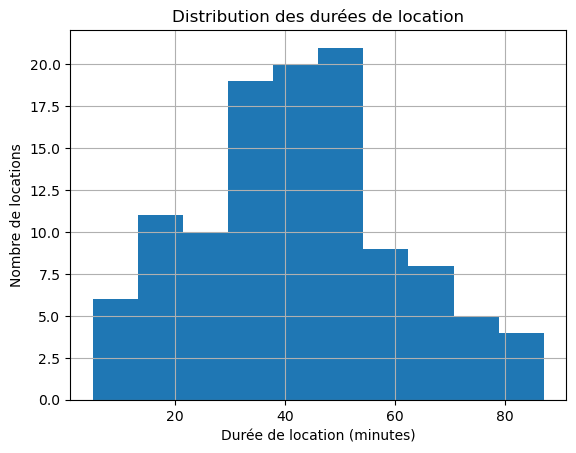

In [41]:
import matplotlib.pyplot as plt

data["duree_min"].hist()
plt.xlabel("Durée de location (minutes)")
plt.ylabel("Nombre de locations")
plt.title("Distribution des durées de location")
plt.show()

<span style="color:blue">**QUESTION : Afficher l'histogramme des distances parcourues.**</span>

<span style="color:red">**CORRECTION :** La méthode `hist()` peut être appelée sur la colonne `distance_km`.</span>

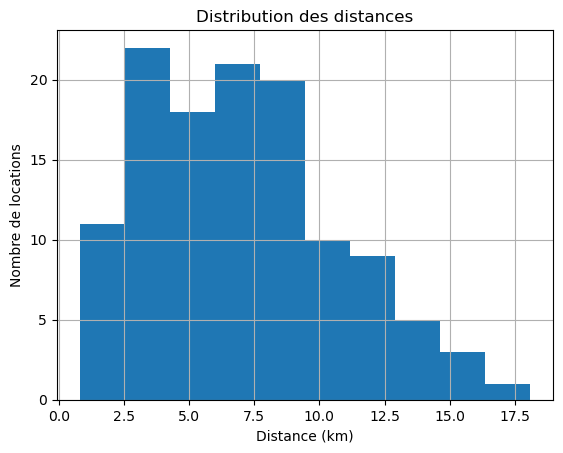

In [42]:
data["distance_km"].hist()
plt.xlabel("Distance (km)")
plt.ylabel("Nombre de locations")
plt.title("Distribution des distances")
plt.show()

## 7. Exercice de synthèse

À partir du DataFrame `data` :

1. affichez sa forme ;
2. comptez le nombre de locations par type de vélo ;
3. sélectionnez les locations de plus de 60 minutes ;
4. calculez le prix moyen par station ;
5. identifiez la station dont le prix moyen est le plus élevé ;
6. calculez la satisfaction moyenne selon le type de vélo ;
7. créez une colonne `prix_par_km` ;
8. construisez un tableau croisé du prix moyen selon la météo et le type de vélo.

<span style="color:blue">**QUESTION : 1. Afficher la forme de `data`.**</span>

<span style="color:red">**CORRECTION :** `shape` renvoie le nombre de lignes et de colonnes.</span>

In [43]:
print(data.shape)

(120, 8)


<span style="color:blue">**QUESTION : 2. Compter le nombre de locations par type de vélo.**</span>

<span style="color:red">**CORRECTION :** `value_counts()` compte les occurrences de chaque valeur.</span>

In [44]:
print(data["type_velo"].value_counts())

Ville         57
Electrique    44
Cargo         19
Name: type_velo, dtype: int64


<span style="color:blue">**QUESTION : 3. Sélectionner les locations de plus de 60 minutes.**</span>

<span style="color:red">**CORRECTION :** On filtre avec un masque booléen sur `duree_min`.</span>

In [45]:
data[data["duree_min"] > 60].head()

,station,type_velo,meteo,duree_min,distance_km,prix_eur,abonne,satisfaction
4,Gare,Ville,Pluie,72.0,8.7,10.76,oui,1.0
9,Antigone,Ville,Soleil,74.0,12.3,10.92,non,1.0
26,Comedie,Ville,Nuageux,72.0,11.4,10.76,non,1.0
33,Port Marianne,Ville,Nuageux,82.0,10.4,11.56,non,4.0
40,Port Marianne,Ville,Pluie,68.0,11.8,10.44,non,3.0


<span style="color:blue">**QUESTION : 4. Calculer le prix moyen par station.**</span>

<span style="color:red">**CORRECTION :** On peut utiliser `groupby` puis `mean`.</span>

In [46]:
prix_station = data.groupby("station")["prix_eur"].mean()
print(prix_station)

station
Antigone         11.740000
Comedie          11.663871
Gare             13.619231
Port Marianne    12.512121
Name: prix_eur, dtype: float64


<span style="color:blue">**QUESTION : 5. Identifier la station dont le prix moyen est le plus élevé.**</span>

<span style="color:red">**CORRECTION :** `idxmax()` renvoie le label associé à la valeur maximale.</span>

In [47]:
prix_station = data.groupby("station")["prix_eur"].mean()
print(prix_station.idxmax())

Gare


<span style="color:blue">**QUESTION : 6. Calculer la satisfaction moyenne selon le type de vélo.**</span>

<span style="color:red">**CORRECTION :** Pandas ignore par défaut les valeurs manquantes lors du calcul de la moyenne.</span>

In [48]:
print(data.groupby("type_velo")["satisfaction"].mean())

type_velo
Cargo         2.722222
Electrique    3.525000
Ville         3.018868
Name: satisfaction, dtype: float64


<span style="color:blue">**QUESTION : 7. Créer une colonne `prix_par_km`.**</span>

<span style="color:red">**CORRECTION :** Les opérations entre colonnes sont vectorisées.</span>

In [49]:
data2 = data.copy()
data2["prix_par_km"] = data2["prix_eur"] / data2["distance_km"]
data2.head()

,station,type_velo,meteo,duree_min,distance_km,prix_eur,abonne,satisfaction,prix_par_km
0,Port Marianne,Electrique,Pluie,46.0,18.1,15.44,oui,5.0,0.853039
1,Comedie,Cargo,Nuageux,37.0,7.3,18.66,oui,5.0,2.556164
2,Port Marianne,Electrique,Pluie,38.0,14.4,14.32,oui,4.0,0.994444
3,Antigone,Ville,Soleil,43.0,5.4,8.44,oui,2.0,1.562963
4,Gare,Ville,Pluie,72.0,8.7,10.76,oui,1.0,1.236782


<span style="color:blue">**QUESTION : 8. Construire un tableau croisé du prix moyen selon la météo et le type de vélo.**</span>

<span style="color:red">**CORRECTION :** On utilise `prix_eur` comme valeur, `meteo` comme index et `type_velo` comme colonnes.</span>

In [50]:
data.pivot_table(values="prix_eur", index="meteo", columns="type_velo", aggfunc="mean")

type_velo,Cargo,Electrique,Ville
meteo,,,
Nuageux,17.14,15.790000,8.618182
Pluie,18.48,14.936000,8.920000
Soleil,19.56,13.861818,8.466667


## À retenir

Avec Pandas, les opérations courantes consistent à :

- **observer** : `head`, `tail`, `shape`, `describe`, `unique` ;
- **sélectionner** : colonnes, `loc`, `iloc` ;
- **filtrer** : masques booléens ;
- **nettoyer** : `fillna`, `ffill`, `dropna`, `drop`, `rename` ;
- **assembler** : `concat` ;
- **résumer** : `groupby`, `pivot_table` ;
- **visualiser rapidement** : `hist`.

L'idée centrale est de manipuler les données à partir de **noms de colonnes explicites** plutôt que de positions numériques difficiles à mémoriser.